<a href="https://colab.research.google.com/github/DannyLe07/Data-201-Project1/blob/main/Data201_Pr1_Danny.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [94]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,KFold, StratifiedKFold, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (confusion_matrix,
                             ConfusionMatrixDisplay,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_curve,
                             roc_auc_score
                             )

In [96]:
heart = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/heart.csv")
heart.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [97]:
heart["target"].value_counts()

,count
target,
1,526
0,499


**Part 1: Understand Your Problem**

**Before modeling anything, understand what you are trying to predict.**

**1. What does each row of your dataset represent? What is your response variable? What are its possible classes?**

Each row represents a different patient. The response variable is target, which represents whether heart disease is present or absent. Its possible class could be binary; 0 would indicate that heart disease is not present and 1 would indicate that heart disease is present.

**2. Select the predictors you believe could be useful for classification.**

Four predictors that could be useful for classification might be age, sex, chol, and thalach.

**3. Examine the distribution of your response variable.
  How many observations belong to each class?
  Is the dataset reasonably balanced or imbalanced?**

There are 526 observations belonging to 1, heart disease present, and 499 observations belonging to 0, heart disease absent. The dataset is reasonably balanced as both classes are roughly a 50/50 split of the total number of observations.

**4. Define a false positive and false negative in the context of your dataset.**

A false positive would be a telling a patient that heart disease is present when it isn't. A false negative would be telling patient that heart disease is absent when in actuality it is present.

**5. Which type of error would you be more concerned about in this application, or are they similarly important? Explain your reasoning**

In this application, false negatives would be a far more concerning error. Failing to diagnose patients properly and sending them home is more dangerous because it allows for the untreated condition to worsen.

In [98]:
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [99]:
heart.dropna()
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [100]:
X = heart[['age', 'sex', 'chol', 'thalach' ]]
y = heart['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0,
)

kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

**Part 2: Explore and Prepare the Data**

**1. Investigate the data**

I used heart.describe()

**2. Determine whether the dataset contains missing values. If it does, explain how you handled them.**

I used heart.dropna() to see if there were any missing values but this dataset does not have any.

**3. Determine whether any categorical predictors need to be encoded before modeling.**

Fortunately for me, all the predictor variables have already be encoded as integers.

**4. Divide the data, then use k-fold CV on training data.**

**5. Determine whether predictors should be standardized for any of the classifiers you will use.**

In [101]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logreg_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    logreg,
    logreg_grid,
    cv=5,
    scoring='roc_auc'
)
grid_lr.fit(X_train, y_train)

logreg_prob = grid_lr.predict_proba(X_test)[:,1]
logreg_pred_50 = grid_lr.predict(X_test)
logreg_pred_30 = np.where(logreg_prob >= 0.30, 1,0 )

In [102]:
lda = LinearDiscriminantAnalysis()

lda_scores = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

lda.fit(X_train, y_train)

lda_pred_50 = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)[:, 1]
lda_pred_30 = np.where(lda_prob >= 0.30, 1,0 )

In [103]:
qda = QuadraticDiscriminantAnalysis()

qda_scores = cross_val_score(
    qda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

qda.fit(X_train, y_train)

qda_pred_50 = qda.predict(X_test)
qda_prob = qda.predict_proba(X_test)[:, 1]
qda_pred_30 = np.where(qda_prob >= 0.30, 1,0 )

In [104]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [1, 3, 5, 11, 21, 51],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=5,
    scoring='roc_auc'
)
grid_knn.fit(X_train, y_train)

knn_pred_50 = grid_knn.predict(X_test)
knn_prob = grid_knn.predict_proba(X_test)[:, 1]
knn_pred_30 = np.where(knn_prob >= 0.30, 1,0 )

In [105]:
print("Logistic Regression best parameters:", grid_lr.best_params_)
print("Logistic Regression best CV ROC-AUC:", round(grid_lr.best_score_, 4))

print("\nLDA mean CV ROC-AUC:", round(lda_scores.mean(), 4))

print("QDA mean CV ROC-AUC:", round(qda_scores.mean(), 4))


print("\nKNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))

Logistic Regression best parameters: {'logisticregression__C': 0.1}
Logistic Regression best CV ROC-AUC: 0.7978

LDA mean CV ROC-AUC: 0.7979
QDA mean CV ROC-AUC: 0.8138

KNN best parameters: {'kneighborsclassifier__n_neighbors': 51, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC-AUC: 0.9966


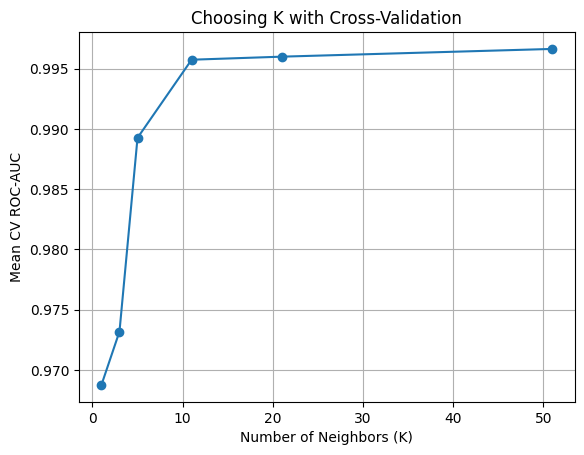

In [106]:
#Graphed using AI

results_df = pd.DataFrame(grid_knn.cv_results_)
uniform_results = results_df[results_df['param_kneighborsclassifier__weights'] == 'distance']

k_values = uniform_results['param_kneighborsclassifier__n_neighbors']
cv_scores = uniform_results['mean_test_score']

plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Choosing K with Cross-Validation")
plt.grid(True)
plt.show()

A K value of 51 was determined to be the best K value when using cross validation on the training data. The grid search automatically searched for the K value that produced the highest ROC-AUC score. Due to the fact that the data contained duplicates, using K=51 alongside distance weights allowed for the model to cheat and find the identical points. This resulted in the artificially inflated Mean CV ROC-AUC value of 0.9966.

In [107]:
cm_logreg_50 = confusion_matrix(y_test, logreg_pred_50)
cm_logreg_30 = confusion_matrix(y_test, logreg_pred_30)
print(cm_logreg_50)
print(cm_logreg_30)

[[90 35]
 [44 88]]
[[ 64  61]
 [  9 123]]


In [108]:
cm_lda_50 = confusion_matrix(y_test, lda_pred_50)
cm_lda_30 = confusion_matrix(y_test, lda_pred_30)

print(cm_lda_50)
print(cm_lda_30)

[[90 35]
 [44 88]]
[[ 70  55]
 [ 11 121]]


In [109]:
cm_qda_50 = confusion_matrix(y_test, qda_pred_50)
cm_qda_30 = confusion_matrix(y_test, qda_pred_30)

print(cm_qda_50)
print(cm_qda_30)

[[99 26]
 [40 92]]
[[ 70  55]
 [ 11 121]]


In [110]:
cm_knn_50 = confusion_matrix(y_test, knn_pred_50)
cm_knn_30 = confusion_matrix(y_test, knn_pred_30)

print(cm_knn_50)
print(cm_knn_30)

[[125   0]
 [  0 132]]
[[125   0]
 [  0 132]]


In [111]:
TN_logreg_50, FP_logreg_50, FN_logreg_50, TP_logreg_50 = cm_logreg_50.ravel()
TN_lda_50, FP_lda_50, FN_lda_50, TP_lda_50 = cm_lda_50.ravel()
TN_qda_50, FP_qda_50, FN_qda_50, TP_qda_50 = cm_qda_50.ravel()
TN_knn_50, FP_knn_50, FN_knn_50, TP_knn_50 = cm_knn_50.ravel()

dataTable_50 = pd.DataFrame({
    "Model": ["Logistic Regression", "LDA", "QDA", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, logreg_pred_50),
        accuracy_score(y_test, lda_pred_50),
        accuracy_score(y_test, qda_pred_50),
        accuracy_score(y_test, knn_pred_50)],
    "Precision": [
        precision_score(y_test, logreg_pred_50),
        precision_score(y_test, lda_pred_50),
        precision_score(y_test, qda_pred_50),
        precision_score(y_test, knn_pred_50)],
    "Recall": [
        recall_score(y_test, logreg_pred_50),
        recall_score(y_test, lda_pred_50),
        recall_score(y_test, qda_pred_50),
        recall_score(y_test, knn_pred_50)],
    "Specificity": [
        TN_logreg_50 / (TN_logreg_50 + FP_logreg_50),
        TN_lda_50 / (TN_lda_50 + FP_lda_50),
        TN_qda_50 / (TN_qda_50 + FP_qda_50),
        TN_knn_50 / (TN_knn_50 + FP_knn_50)],
    "F1": [
        f1_score(y_test, logreg_pred_50),
        f1_score(y_test, lda_pred_50),
        f1_score(y_test, qda_pred_50),
        f1_score(y_test, knn_pred_50)],
    "ROC-AUC": [
        roc_auc_score(y_test, logreg_prob),
        roc_auc_score(y_test, lda_prob),
        roc_auc_score(y_test, qda_prob),
        roc_auc_score(y_test, knn_prob)],
})
dataTable_50

,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Logistic Regression,0.692607,0.715447,0.666667,0.720,0.690196,0.811939
1,LDA,0.692607,0.715447,0.666667,0.720,0.690196,0.810545
2,QDA,0.743191,0.779661,0.696970,0.792,0.736000,0.822121
3,KNN,1.000000,1.000000,1.000000,1.000,1.000000,1.000000


In [112]:
TN_logreg_30, FP_logreg_30, FN_logreg_30, TP_logreg_30 = cm_logreg_30.ravel()
TN_lda_30, FP_lda_30, FN_lda_30, TP_lda_30 = cm_lda_30.ravel()
TN_qda_30, FP_qda_30, FN_qda_30, TP_qda_30 = cm_qda_30.ravel()
TN_knn_30, FP_knn_30, FN_knn_30, TP_knn_30 = cm_knn_30.ravel()

dataTable_30 = pd.DataFrame({
    "Model": ["Logistic Regression", "LDA", "QDA", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, logreg_pred_30),
        accuracy_score(y_test, lda_pred_30),
        accuracy_score(y_test, qda_pred_30),
        accuracy_score(y_test, knn_pred_30)],
    "Precision": [
        precision_score(y_test, logreg_pred_30),
        precision_score(y_test, lda_pred_30),
        precision_score(y_test, qda_pred_30),
        precision_score(y_test, knn_pred_30)],
    "Recall": [
        recall_score(y_test, logreg_pred_30),
        recall_score(y_test, lda_pred_30),
        recall_score(y_test, qda_pred_30),
        recall_score(y_test, knn_pred_30)],
    "Specificity": [
        TN_logreg_30 / (TN_logreg_30 + FP_logreg_30),
        TN_lda_30 / (TN_lda_30 + FP_lda_30),
        TN_qda_30 / (TN_qda_30 + FP_qda_30),
        TN_knn_30 / (TN_knn_30 + FP_knn_30)],
    "F1": [
        f1_score(y_test, logreg_pred_30),
        f1_score(y_test, lda_pred_30),
        f1_score(y_test, qda_pred_30),
        f1_score(y_test, knn_pred_30)],
    "ROC-AUC": [
        roc_auc_score(y_test, logreg_prob),
        roc_auc_score(y_test, lda_prob),
        roc_auc_score(y_test, qda_prob),
        roc_auc_score(y_test, knn_prob)],
})
dataTable_30

,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Logistic Regression,0.727626,0.668478,0.931818,0.512,0.778481,0.811939
1,LDA,0.743191,0.687500,0.916667,0.560,0.785714,0.810545
2,QDA,0.743191,0.687500,0.916667,0.560,0.785714,0.822121
3,KNN,1.000000,1.000000,1.000000,1.000,1.000000,1.000000


**Part 5: Reflect**

**Explain what you discover. Based on the consequences of false positives and false negatives that you discussed in Part 1, which metrics are particularly informative for this application? Explain.**

I will be using the 0.30 data table as I found that one to be better for this dataset. The metrics that are particulary informative would be recall, precision, and specificity. The recall score indicates that of all actual sick patients, we were able to catch 91% or more in each model. However, the trade off is more false positives, claiming that heart disease is present in patients who actually don't have heart disease, which is demonstrated by the low precision score and the low specificity score.

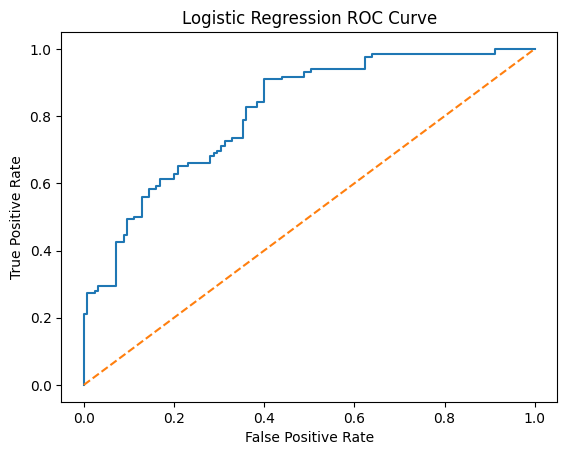

0.811939393939394


In [113]:
fpr_logreg, tpr_logreg, thresholds_logreg = roc_curve(
    y_test,
    logreg_prob
)

plt.plot(
    fpr_logreg,
    tpr_logreg
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve")

plt.show()

print(roc_auc_score(y_test, logreg_prob))

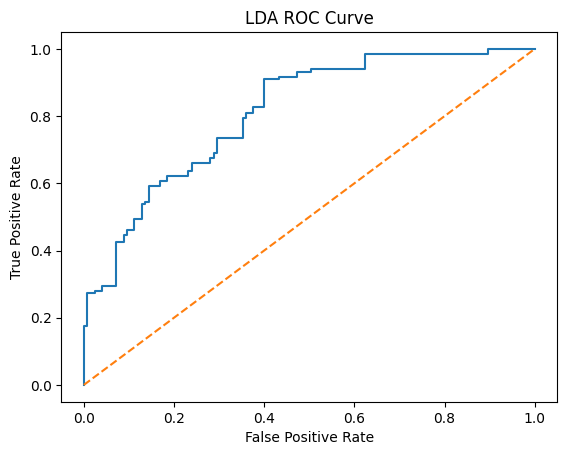

0.8105454545454546


In [114]:
fpr_lda, tpr_lda, thresholds_lda = roc_curve(
    y_test,
    lda_prob
)

plt.plot(
    fpr_lda,
    tpr_lda
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA ROC Curve")

plt.show()

print(roc_auc_score(y_test, lda_prob))

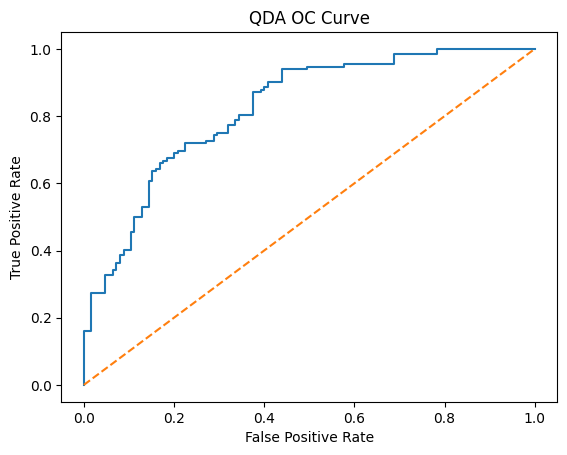

0.8221212121212121


In [115]:
fpr_qda, tpr_qda, thresholds_qda = roc_curve(
    y_test,
    qda_prob
)

plt.plot(
    fpr_qda,
    tpr_qda
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("QDA OC Curve")

plt.show()

print(roc_auc_score(y_test, qda_prob))

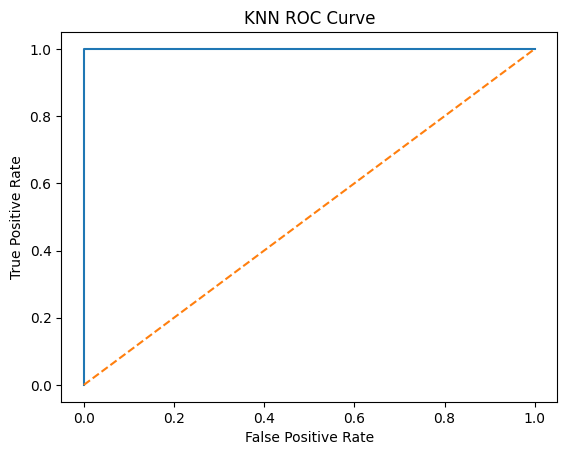

1.0


In [116]:
fpr_knn, tpr_knn, thresholds_knn = roc_curve(
    y_test,
    knn_prob
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label = ''
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")

plt.show()
print(roc_auc_score(y_test, knn_prob))

**Part 6: ROC and AUC**

**Plot its ROC curve and report its ROC-AUC. Explain in your own words what ROC-AUC tells us.**

ROC-AUC score indicates to us how well the model can rank positive cases to negative cases at any given threshold. A high ROC-AUC score represents that the model has a high recall and a low false positive rate. We will disregard the KNN ROC-AUC curve and score as data cleaning has led it to have an artificially crafted perfect score of 1. The classifer with the highest ROC-AUC score was QDA. The QDA ROC-AUC score of about 0.822 means that the model has a 82.2% probability to correctly rank a patient with heart disease higher than a patient without heart disease.

**Part 7: Final Analysis**

**Imagine that you are presenting your findings to someone who understands the problem but has not taken DATA 201.**

**1- Compare the performance of your four classifiers. What are the most important differences?**

**2- Identify the model you would deploy for this specific application and justify the choice using your results and the consequences of classification errors.**

**3- Explain one limitation of your analysis.**

**Examples could include:

**a. dataset size**

**b. class imbalance**

**c. available predictors**

**d. missing information**

**4. What additional information or data would you want before using this model in the real world?**


Due to the uncertainity of not knowing if some patients' data were duplicates, I will be disregarding KNN as all the results were artificially crafted to be 1. The three remaining classifiers of Logistic Regression, LDA, and QDA, were all quite similar. When the threshold was 0.50, Logistic Regression and LDA had the same results while QDA had slightly higher results for each metric. When the threshold was 0.30, all the classifiers were much closer, LDA and QDA were identical. The most important differences were the recall score and the ROC-AUC score (unaffected by threshold). While Logistic Regression had a slightly higher recall score, QDA beat it out in every other metric. Additionally, QDA had the highest ROC-AUC score of the three. Thus, the model I would deploy for this application is the QDA model. One of the major limitations of my analysis was something I mentioned prior, the overcleaning of the dataset. Due to the fact that it was overcleaned, there are some rows with the exact same data. I could not drop those rows as without more information, there is no telling if there are actually patients with the same data or if it is duplicates of the same patient. Due to this limitation, I was not fully able to determine whether or not KNN could have been a good model for this application. I think additional data I would want before using this model in the real world is a patient's family history, like if they are prone to heart disease due to genetics, and maybe a patient's race.